# 02 · Libro → temas

Clasificación multi-etiqueta (40 temas) a partir del título y la descripción. Partición **agrupada por
autor**: los libros de test son de autores que el modelo nunca vio. Resultados de `run.py`.

In [1]:
import json

import numpy as np
import pandas as pd
from book_topics import MODULE

from common import data_dir, setup_style

setup_style()
d = data_dir(MODULE)
P = d.parent
report = json.loads((P / "resultados" / "metrics.json").read_text())
a = report["parte_a"]
print("libros:", a["n_libros"])
pd.DataFrame(
    {
        m: {k: r[k] for k in ("micro_f1", "macro_f1", "precision_at_3", "ece")}
        for m, r in a["modelos"].items()
    }
).T.round(3)

libros: {'train': 6690, 'val': 810, 'test': 2123}


,micro_f1,macro_f1,precision_at_3,ece
logistica,0.644,0.550,0.695,0.005
knn,0.589,0.488,0.602,0.030
prevalencia,0.249,0.124,0.249,0.003
lectores,0.663,0.445,0.638,0.042


## 1. H1 y la pregunta exploratoria

In [2]:
def fmt(h):
    lo, hi = h["ci"]
    return f"Δ = {h['diff']:+.4f}  IC 95 % [{lo:+.4f}, {hi:+.4f}]  p = {h['p_value']:.4f}"


h1 = report["hipotesis"]["H1"]
print("H1 logística − k vecinos (F1-macro):", fmt(h1), f"p_Holm = {h1['p_holm']:.4f}")
print("Exploratoria texto − lectores (F1-macro):", fmt(a["exploratoria_texto_vs_lectores"]))

H1 logística − k vecinos (F1-macro): Δ = +0.0626  IC 95 % [+0.0474, +0.0771]  p = 0.0005 p_Holm = 0.0015
Exploratoria texto − lectores (F1-macro): Δ = +0.1050  IC 95 % [+0.0796, +0.1301]  p = 0.0005


**Lectura.** H1 se apoya: la logística supera a k vecinos por +0,063 de F1-macro (IC 95 % [0,047;
0,077], p_Holm = 0,0015; p = 0,0005 es el piso del bootstrap con 2 000 réplicas, así que se reporta
"< 0,0005"). La logística además está bien calibrada (ECE 0,005).

La exploratoria es más interesante: el **texto** le gana a los **lectores** (vector de cada libro en el
espacio ALS de las calificaciones) por +0,105 de F1-macro, aunque los lectores ganan en F1-micro (0,663
frente a 0,644). Los lectores aciertan los temas grandes; el texto distingue mejor los pequeños.

## 2. ¿Dónde falla?

Spearman prevalencia vs. F1: 0.58


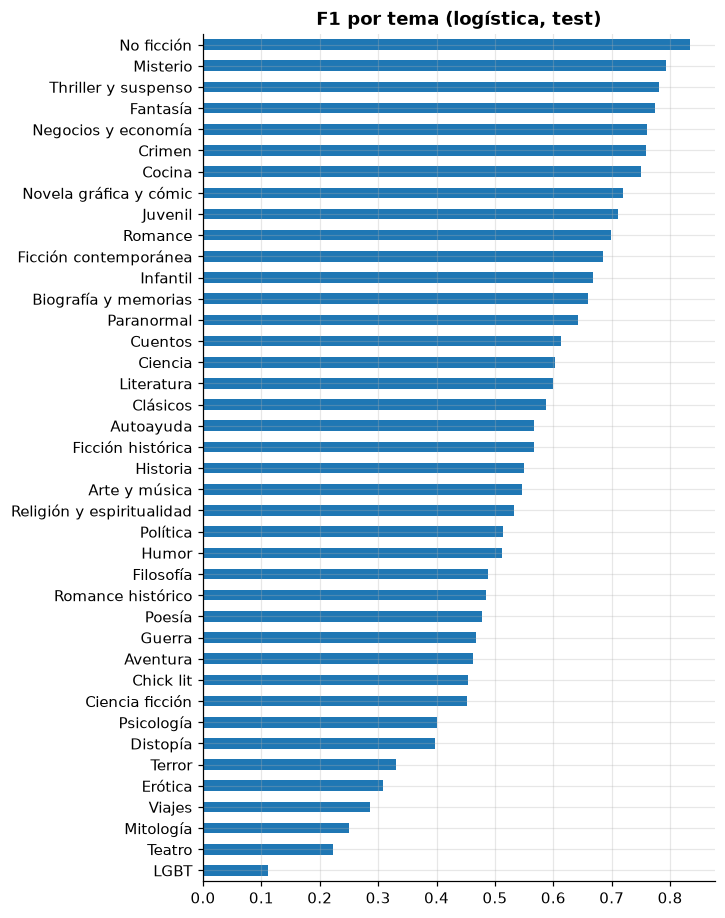

In [3]:
from book_topics.taxonomy import load_taxonomy

names = {t.key: t.nombre for t in load_taxonomy(P / "temas.yaml")}
f1 = pd.Series(a["modelos"]["logistica"]["per_topic_f1"]).rename(index=names).sort_values()
f1.plot.barh(figsize=(6, 10), title="F1 por tema (logística, test)")
print(f"Spearman prevalencia vs. F1: {a['spearman_prevalencia_f1']:.2f}")

In [4]:
conf = pd.DataFrame(a["confusiones"], columns=["falsos positivos", "predicho", "real"])
conf[["predicho", "real"]] = conf[["predicho", "real"]].replace(names)
print(conf.to_string(index=False))
print(
    "F1-micro por cuartil de largo de la descripción:",
    {int(k): round(v, 3) for k, v in a["f1_por_cuartil_largo"].items()},
)

 falsos positivos predicho                  real
              126 Aventura              Fantasía
               77  Juvenil              Fantasía
               72  Romance              Fantasía
               67  Romance               Juvenil
               66    Humor Ficción contemporánea
F1-micro por cuartil de largo de la descripción: {0: 0.566, 1: 0.653, 2: 0.676, 3: 0.676}


**Lectura.** La F1 por tema sigue a la prevalencia (Spearman 0,58): los temas raros se aprenden peor.
Las confusiones principales son todas *hacia* fantasía o desde géneros vecinos (aventura → fantasía
126 veces, juvenil → fantasía 77): son fronteras difusas también para los lectores. Y la descripción
importa: el cuartil más corto tiene F1-micro 0,566 contra 0,676 de los dos más largos.

## 3. Ejemplos de libros de test

In [5]:
from book_topics.artifacts import load_bundle, predict_topics
from book_topics.classify import book_text

b = load_bundle(d / "modelos" / "bundle.joblib")
test_ids = b.test_ids  # los mismos libros de test que en run.py (autores no vistos)
topic_names = [t.nombre for t in b.topics]
for bid in (test_ids[0], test_ids[5], test_ids[40]):
    row = b.books[b.books.book_id == bid].iloc[0]
    _, assigned = predict_topics(
        b, [book_text(pd.Series([row.title], index=[bid]), b.descriptions).iloc[0]]
    )
    real = [topic_names[j] for j in np.flatnonzero(b.labels.loc[bid].to_numpy())]
    pred = [topic_names[j] for j in np.flatnonzero(assigned[0])]
    print(f"{row.title}\n  reales:    {', '.join(real)}\n  predichos: {', '.join(pred)}\n")

The Great Gatsby
  reales:    Ficción histórica, Clásicos, Literatura
  predichos: Ficción histórica, Clásicos, Literatura

The Alchemist
  reales:    Fantasía, Clásicos, Literatura, Ficción contemporánea, Autoayuda, Filosofía, Religión y espiritualidad
  predichos: Literatura

Marley and Me: Life and Love With the World's Worst Dog
  reales:    Humor, No ficción, Biografía y memorias
  predichos: Romance, Ficción contemporánea



**Lectura.** Tres libros de autores que el modelo nunca vio: *The Great Gatsby* sale perfecto; de los
7 temas de *The Alchemist* solo acierta "Literatura" (sus temas de autoayuda/espiritualidad vienen de
cómo lo leen, no de lo que dice la sinopsis); *Marley and Me* sale como romance/contemporánea en vez de
memorias con humor. Ese es el techo del TF-IDF: palabras, no intención.

> En la primera versión de este notebook los tres ejemplos salían *perfectos*. La causa: el bundle de
> la CLI filtraba los libros con otro criterio que `run.py` y 1 651 de los 2 123 libros de "test"
> estaban en su entrenamiento. Se corrigió con `usable_books` compartido y `Bundle.test_ids`.